### Задача 4. Реализация поиска кратчайших путей

Везде считаем, что вершины графа занумерованы подряд с нуля. Обратите внимание на то, что про граф заранее не известно, есть ли в нём циклы отрицательного веса.

In [12]:
import pandas as pd
import numpy as np
import graphblas as gb
from graphblas.io import mmread
import networkx as nx
import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from warnings import filterwarnings

filterwarnings('ignore')
plt.style.use('bmh')
sns.set_theme(style="whitegrid")

**1. Используя `python-graphblas` реализовать функцию поиска кратчайших путей в ориентированном графе из заданной вершины (Bellman–Ford).**

- Функция принимает представление графа, удобное для неё (загрузка, конвертация реализованы отдельно) и номер стартовой вершины.

- Функция возвращает массив, где для каждой вершины указано расстояние до неё от указанной стартовой вершины. Если вершина не достижима или кратчайшего пути для неё не существует, то значение соответствующей ячейки равно float('inf').

In [ ]:
def bellman_ford(A: gb.Matrix, start_vertex: int) -> list[float]:
    n = A.nrows
    v = gb.Vector(float, size=n)
    v[start_vertex] = 0.0
    
    for _ in range(n - 1):
        v_old = v.dup()
        v(accum=gb.binary.min) << v.vxm(A, gb.semiring.min_plus)
        
        if v.isequal(v_old):
            break
            
    # Проверка на наличие циклов отрицательного веса
    v_old = v.dup()
    v(accum=gb.binary.min) << v.vxm(A, gb.semiring.min_plus)
    
    affected = gb.Vector(bool, size=n)
    has_negative_cycle = False
    
    if not v.isequal(v_old):
        has_negative_cycle = True
        
        for i in range(n):
            val_old = v_old.get(i)
            val_new = v.get(i)
            if val_new is not None and (val_old is None or val_new < val_old):
                affected[i] = True
                
        for _ in range(n - 1):
            affected_old = affected.dup()
            affected(accum=gb.binary.lor) << affected.vxm(A, gb.semiring.any_pair)
            
            if affected.isequal(affected_old):
                break

    result = [float('inf')] * n
    for i in range(n):
        if has_negative_cycle and affected.get(i, False):
            pass 
        else:
            dist = v.get(i)
            if dist is not None:
                result[i] = dist
                
    return result

**2. Используя `python-graphblas` реализовать функцию поиска кратчайших путей в ориентированном графе из нескольких заданных вершин, модифицировав предыдущий алгоритм.**

- Функция принимает представление графа, удобное для неё (загрузка, конвертация реализованы отдельно) и массив номеров стартовых вершин.

- Функция возвращает массив пар: вершина, и массив, где для каждой вершины указано расстояние до неё из указанной. Если вершина не достижима или кратчайшего пути для неё не существует, то значение соответствующей ячейки равно float('inf').

In [ ]:
def bellman_ford_mssp(A: gb.Matrix, start_vertices: list[int]) -> list[tuple[int, list[float]]]:
    n = A.nrows
    k = len(start_vertices)
    D = gb.Matrix(float, nrows=k, ncols=n)
    
    for i, start_v in enumerate(start_vertices):
        D[i, start_v] = 0.0
        
    for _ in range(n - 1):
        D_old = D.dup()
        D(accum=gb.binary.min) << D.mxm(A, gb.semiring.min_plus)
        
        if D.isequal(D_old):
            break
            
    D_old = D.dup()
    D(accum=gb.binary.min) << D.mxm(A, gb.semiring.min_plus)
    
    affected = gb.Matrix(bool, nrows=k, ncols=n)
    has_negative_cycle = False
    
    if not D.isequal(D_old):
        has_negative_cycle = True
        
        rows, cols, vals = D.to_coo()
        for i, j, val_new in zip(rows, cols, vals):
            val_old = D_old.get(i, j)
            if val_old is None or val_new < val_old:
                affected[i, j] = True
                
        for _ in range(n - 1):
            affected_old = affected.dup()
            affected(accum=gb.binary.lor) << affected.mxm(A, gb.semiring.any_pair)
            
            if affected.isequal(affected_old):
                break

    result = []
    for i, start_v in enumerate(start_vertices):
        row_dist = [float('inf')] * n
        for j in range(n):

            if has_negative_cycle and affected.get(i, j) is True:
                pass 
            else:
                dist = D.get(i, j)
                if dist is not None:
                    row_dist[j] = dist
                    
        result.append((start_v, row_dist))
        
    return result

**3. Используя `python-graphblas` реализовать две функции поиска кратчайших путей в ориентированном графе для всех пар вершин (Floyd–Warshall и вычисление транзитивного замыкания).**

- Функции принимают представление графа, удобное для неё (загрузка, конвертация реализованы отдельно).

- Функции возвращают массив пар: вершина, и массив, где для каждой вершины указано расстояние до неё из указанной. Если вершина не достижима или кратчайшего пути для неё не существует, то значение соответствующей ячейки равно float('inf').

In [ ]:
def floyd_warshall(A: gb.Matrix) -> list[tuple[int, list[float]]]:
    n = A.nrows
    D = A.dup(dtype=float)
    
    diag_vec = gb.Vector(float, size=n)
    diag_vec[:] = 0.0
    D(accum=gb.binary.min) << gb.Matrix.diag(diag_vec)
    
    # Основной цикл Флойда-Уоршелла
    for k in range(n):
        col = D[:, [k]].new()
        row = D[[k], :].new()
    
        D(accum=gb.binary.min) << col.mxm(row, gb.semiring.min_plus)
        
    result = []
    for i in range(n):
        row_dist = [float('inf')] * n
        for j in range(n):
            dist = D.get(i, j)
            if dist is not None:
                row_dist[j] = dist
                
        # Проверка на отрицательные циклы
        if D.get(i, i) is not None and D.get(i, i) < 0.0:
            row_dist = [float('inf')] * n 
            
        result.append((i, row_dist))
        
    return result


def transitive_closure(A: gb.Matrix) -> list[tuple[int, list[float]]]:
    n = A.nrows
    T = A.dup(dtype=bool)
    
    diag_vec = gb.Vector(bool, size=n)
    diag_vec[:] = True
    T(accum=gb.binary.lor) << gb.Matrix.diag(diag_vec)
    
    while True:
        T_old = T.dup()
        T(accum=gb.binary.lor) << T.mxm(T, gb.semiring.lor_land)
        
        if T.isequal(T_old):
            break
            
    result = []
    for i in range(n):
        row_dist = [float('inf')] * n
        for j in range(n):
            if T.get(i, j, False) is True:
                row_dist[j] = 0.0 if i == j else 1.0
        result.append((i, row_dist))
        
    return result

**4. Добавить необходимые тесты.**

In [5]:
def create_matrix(edges, n):
    m = gb.Matrix(float, n, n)
    for u, v, w in edges:
        m[u, v] = float(w)
    return m


def test_single_vertex():
    A = gb.Matrix(float, 1, 1)
    assert bellman_ford(A, 0) == [0.0]
    
    res_mssp = bellman_ford_mssp(A, [0])
    assert res_mssp == [(0, [0.0])]
    
    res_floyd = floyd_warshall(A)
    assert res_floyd == [(0, [0.0])]
    
    res_tc = transitive_closure(A)
    assert res_tc == [(0, [0.0])]

def test_empty_graph():
    A = gb.Matrix(float, 0, 0)

    try:
        bellman_ford(A, 0)
    except (ValueError, IndexError, gb.exceptions.IndexOutOfBound):
        pass 
        
    assert bellman_ford_mssp(A, []) == []
    assert floyd_warshall(A) == []
    assert transitive_closure(A) == []

def test_unreachable_components():
    edges = [(0, 1, 5), (2, 3, 10)]
    n = 4
    A = create_matrix(edges, n)
    
    assert bellman_ford(A, 0) == [0.0, 5.0, float('inf'), float('inf')]
    
    fw_res = dict(floyd_warshall(A))
    assert fw_res[0] == [0.0, 5.0, float('inf'), float('inf')]
    assert fw_res[2] == [float('inf'), float('inf'), 0.0, 10.0]

test_single_vertex()
test_empty_graph()
test_unreachable_components()

# bellman_ford, простой граф без циклов
edges = [(0, 1, 5), (1, 2, 3)]
A = create_matrix(edges, 3)
assert bellman_ford(A, 0) == [0.0, 5.0, 8.0]
assert bellman_ford(A, 1) == [float('inf'), 0.0, 3.0]

# bellman_ford, граф с отрицательным ребром, но без отрицательного цикла
edges = [(0, 1, 10), (1, 2, -2), (0, 2, 15)]
A = create_matrix(edges, 3)
assert bellman_ford(A, 0) == [0.0, 10.0, 8.0]

# bellman_ford, граф с отрицательным циклом
edges = [(0, 1, 5), (1, 2, -2), (2, 1, 1)]
A = create_matrix(edges, 3)
res = bellman_ford(A, 0)
assert res[0] == 0.0
assert res[1] == float('inf')
assert res[2] == float('inf')


# mssp
edges = [(0, 1, 10), (2, 1, 5)]
A = create_matrix(edges, 3)
results = bellman_ford_mssp(A, [0, 2])
assert results[0][0] == 0
assert results[0][1] == [0.0, 10.0, float('inf')]
assert results[1][0] == 2
assert results[1][1] == [float('inf'), 5.0, 0.0]

# mssp, список стартовых вершин пуст
edges = [(0, 1, 5)]
A = create_matrix(edges, 2)
assert bellman_ford_mssp(A, []) == []


# floyd_warshall, треугольник
edges = [(0, 1, 1), (1, 2, 2), (2, 0, 6)]
A = create_matrix(edges, 3)
res = floyd_warshall(A)
assert res[0][1] == [0.0, 1.0, 3.0]
assert res[2][1] == [6.0, 7.0, 0.0]

# floyd_warshall, отрицательный цикл на вершине 1 (петля -1)
edges = [(0, 1, 5), (1, 1, -1)]
A = create_matrix(edges, 2)
res = floyd_warshall(A)
assert res[1][1] == [float('inf'), float('inf')]

# floyd_warshall, Петля
edges = [(0, 0, 10), (0, 1, 5)]
A = create_matrix(edges, 2)
res = floyd_warshall(A)
assert res[0][1][0] == 0.0
assert res[0][1][1] == 5.0


# transitive_closure, линейный граф
edges = [(0, 1, 100), (1, 2, 0.5)]
A = create_matrix(edges, 3)
res = transitive_closure(A)
assert res[0][1] == [0.0, 1.0, 1.0]
assert res[2][1] == [float('inf'), float('inf'), 0.0]

# transitive_closure, полный граф
n = 4
edges = [(i, j, 1) for i in range(n) for j in range(n) if i != j]
A = create_matrix(edges, n)
res = transitive_closure(A)
for i in range(n):
    assert all(d != float('inf') for d in res[i][1])


print('Все тесты успешно пройдены!')

Все тесты успешно пройдены!


**5. Провести экспериментальное исследование полученных реализаций на некоторых больших графах в формате `Matrix Market` с сайта SuiteSparse Matrix Collection и на случайных сгенерированных. При этом описать зависимость времени работы всех полученных реализаций от размеров графа, его степени разреженности, количестве стартовых вершин. В частности выяснить, начиная с какой доли вершин в графе целесообразнее использовать алгоритм поиска кратчайших путей для всех пар вершин вместо того, чтобы решать задачу поиска кратчайших путей из нескольких стартовых (модифицированный Bellman-Ford).**

In [6]:
os.listdir('./data')

['494_bus.mtx', '685_bus.mtx', 'bcspwr09.mtx', 'dwt_992.mtx', 'lshp3025.mtx']

In [7]:
def run_experiments():
    results = []
    
    # тестирование на реальных графах Matrix Market
    data_dir = './data'

    for filename in tqdm(os.listdir(data_dir)):
        filepath = os.path.join(data_dir, filename)
        A = mmread(filepath)

        n = A.nrows
        nnz = A.nvals
        density = nnz / (n * n) if n > 0 else 0

        t_floyd = None
        t_closure = None
        if n <= 2000:
            t_start = time.perf_counter()
            floyd_warshall(A)
            t_floyd = time.perf_counter() - t_start
            
            t_start = time.perf_counter()
            transitive_closure(A)
            t_closure = time.perf_counter() - t_start
        
        for k in [1, 10, 50]:
            if k > n: continue
            starts = np.random.choice(n, k, replace=False).tolist()
            
            t_start = time.perf_counter()
            for s in starts:
                bellman_ford(A, s)
            t_bellman = time.perf_counter() - t_start
            
            t_start = time.perf_counter()
            bellman_ford_mssp(A, starts)
            t_mssp = time.perf_counter() - t_start
            
            results.append({
                'Graph': filename, 'N': n, 'Edges': nnz, 'Density': density,
                'Num_Starts (K)': k, 'Time_bellman (s)': t_bellman, 'Time_mssp (s)': t_mssp,
                'Time_floyd (s)': t_floyd, 'Time_closure (s)': t_closure
            })

    # тестирование на сгенерированных графах (влияние размера и плотности)
    sizes = [500, 1000, 2000]
    densities = [0.001, 0.01, 0.05]
    k_starts = [1, 10, 50]
    
    for n in tqdm(sizes):
        for p in densities:
            # генерация случайного разреженного графа
            G = nx.fast_gnp_random_graph(n, p, directed=True)
            edges = list(G.edges())
            if not edges: continue
            rows, cols = zip(*edges)
            A = gb.Matrix.from_coo(rows, cols, [True]*len(rows), nrows=n, ncols=n)

            t_floyd = None
            t_closure = None
            if n <= 2000:
                t_start = time.perf_counter()
                floyd_warshall(A)
                t_floyd = time.perf_counter() - t_start
                
                t_start = time.perf_counter()
                transitive_closure(A)
                t_closure = time.perf_counter() - t_start
            
            for k in k_starts:
                starts = np.random.choice(n, k, replace=False).tolist()
                
                t_start = time.perf_counter()
                for s in starts:
                    bellman_ford(A, s)
                t_bellman = time.perf_counter() - t_start
                
                t_start = time.perf_counter()
                bellman_ford_mssp(A, starts)
                t_mssp = time.perf_counter() - t_start   

                results.append({
                    'Graph': f'Random_N{n}_p{p}', 'N': n, 'Edges': len(edges), 'Density': p,
                    'Num_Starts (K)': k, 'Time_bellman (s)': t_bellman, 'Time_mssp (s)': t_mssp,
                    'Time_floyd (s)': t_floyd, 'Time_closure (s)': t_closure
                })
            
    df_results = pd.DataFrame(results)
    return df_results

df = run_experiments()
df

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

,Graph,N,Edges,Density,Num_Starts (K),Time_bellman (s),Time_mssp (s),Time_floyd (s),Time_closure (s)
0,494_bus.mtx,494,1666,0.006827,1,0.037185,0.034106,3.349370,3.030229
1,494_bus.mtx,494,1666,0.006827,10,0.353019,0.191854,3.349370,3.030229
2,494_bus.mtx,494,1666,0.006827,50,1.878503,0.916274,3.349370,3.030229
3,685_bus.mtx,685,3249,0.006924,1,0.052397,0.048782,6.657814,5.837319
4,685_bus.mtx,685,3249,0.006924,10,0.509273,0.290735,6.657814,5.837319
5,685_bus.mtx,685,3249,0.006924,50,2.547447,1.357525,6.657814,5.837319
6,bcspwr09.mtx,1723,6511,0.002193,1,0.019168,0.022859,38.376329,37.499143
7,bcspwr09.mtx,1723,6511,0.002193,10,0.196535,0.229596,38.376329,37.499143
8,bcspwr09.mtx,1723,6511,0.002193,50,0.996062,1.135664,38.376329,37.499143
9,dwt_992.mtx,992,16744,0.017015,1,0.011301,0.013214,16.001631,12.224933


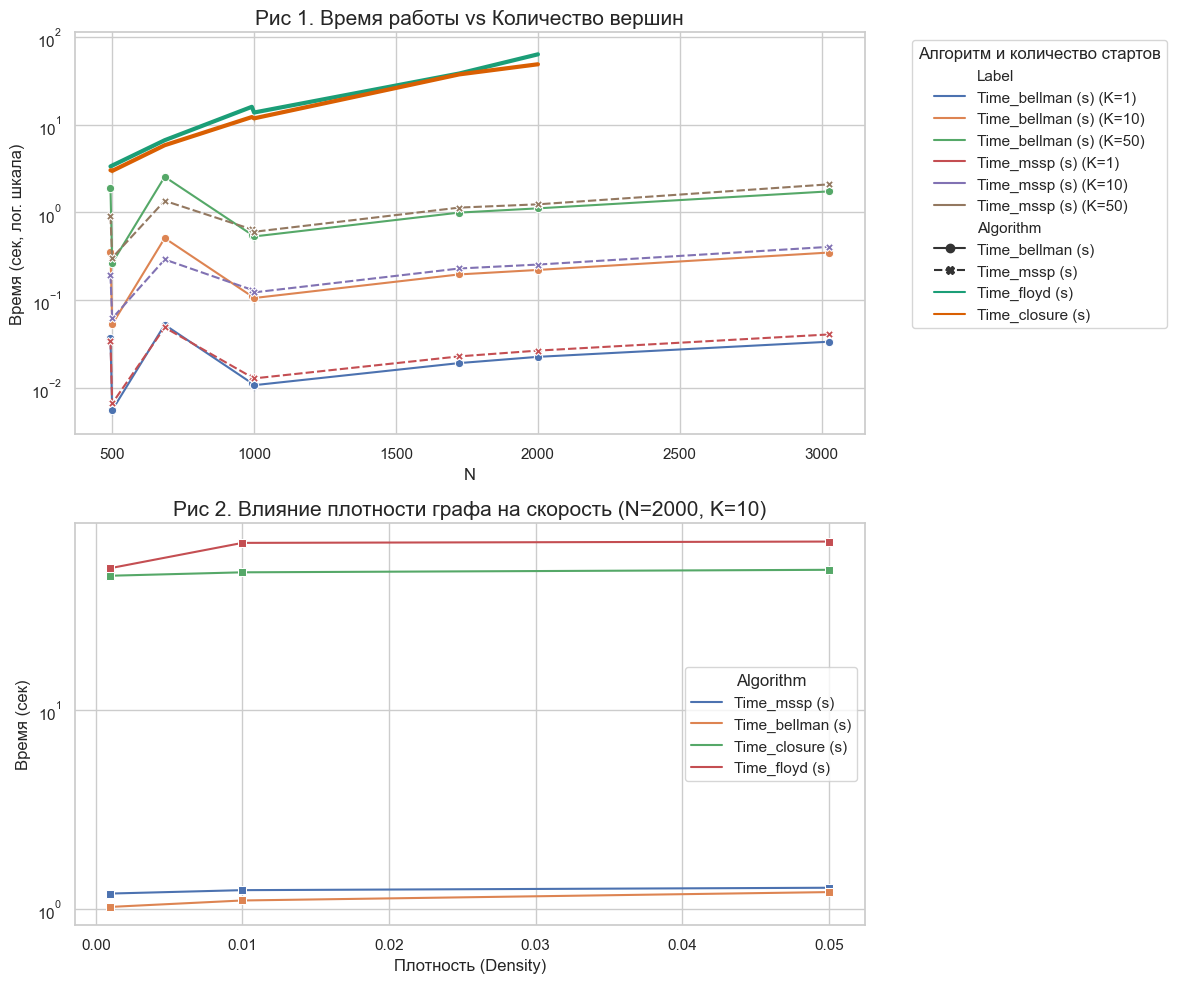

In [ ]:
def plot_results(df):
    plt.rcParams['figure.figsize'] = [12, 10]
    fig, axes = plt.subplots(2, 1)

    # Масштабируемость от N и влияние K
    df_mssp = df.melt(id_vars=['N', 'Num_Starts (K)'], 
                      value_vars=['Time_bellman (s)', 'Time_mssp (s)'],
                      var_name='Algorithm', value_name='Time')
    df_mssp['Label'] = df_mssp['Algorithm'] + " (K=" + df_mssp['Num_Starts (K)'].astype(str) + ")"

    df_apsp = df[df['Num_Starts (K)'] == df['Num_Starts (K)'].min()].melt(
                      id_vars=['N'], 
                      value_vars=['Time_floyd (s)', 'Time_closure (s)'],
                      var_name='Algorithm', value_name='Time')
    df_apsp['Label'] = df_apsp['Algorithm']

    sns.lineplot(data=df_mssp, x='N', y='Time', hue='Label', style='Algorithm', markers=True, ax=axes[0])
    sns.lineplot(data=df_apsp, x='N', y='Time', hue='Label', palette='Dark2', linewidth=3, ax=axes[0])
    
    axes[0].set_yscale('log')
    axes[0].set_title('Рис 1. Время работы vs Количество вершин', fontsize=15)
    axes[0].set_ylabel('Время (сек, лог. шкала)')
    axes[0].legend(title='Алгоритм и количество стартов', bbox_to_anchor=(1.05, 1), loc='upper left')

    # Зависимость от плотности 
    n_fixed = 2000
    df_density = df[(df['N'] == n_fixed) & (df['Num_Starts (K)'] == 50)]
    
    df_melted_density = df_density.melt(id_vars=['Density'], 
                                        value_vars=['Time_mssp (s)', 'Time_bellman (s)', 'Time_closure (s)', 'Time_floyd (s)'],
                                        var_name='Algorithm', value_name='Time')

    sns.lineplot(data=df_melted_density, x='Density', y='Time', hue='Algorithm', marker='s', ax=axes[1])
    axes[1].set_title(f'Рис 2. Влияние плотности графа на скорость (N={n_fixed}, K=10)', fontsize=15)
    axes[1].set_ylabel('Время (сек)')
    axes[1].set_yscale('log')
    axes[1].set_xlabel('Плотность (Density)')

    plt.tight_layout()
    plt.show()

plot_results(df)